In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

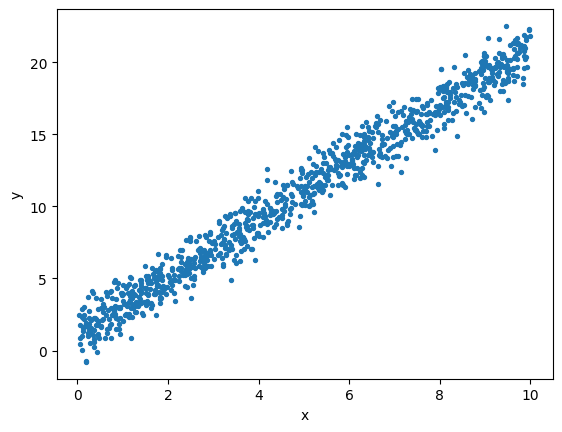

In [2]:
np.random.seed(42)
x = np.random.uniform(0, 10, 1000)
y = 2 * x + 1 + np.random.normal(0, 1, 1000)
plt.scatter(x, y, s=8)
plt.xlabel("x")
plt.ylabel("y")
plt.show()

K = 1  RMSE = 0.0618
K = 2  RMSE = 0.052
K = 3  RMSE = 0.0486
K = 4  RMSE = 0.0462
K = 5  RMSE = 0.0449
K = 6  RMSE = 0.0442
K = 7  RMSE = 0.0434
K = 8  RMSE = 0.0428
K = 9  RMSE = 0.0424
K = 10  RMSE = 0.0422
K = 11  RMSE = 0.042
K = 12  RMSE = 0.0421
K = 13  RMSE = 0.0418
K = 14  RMSE = 0.0417
K = 15  RMSE = 0.0416
K = 16  RMSE = 0.0414
K = 17  RMSE = 0.0412
K = 18  RMSE = 0.0412
K = 19  RMSE = 0.0412
K = 20  RMSE = 0.0412
K = 21  RMSE = 0.0413
K = 22  RMSE = 0.0409
K = 23  RMSE = 0.0411
K = 24  RMSE = 0.0411
K = 25  RMSE = 0.0411
K = 26  RMSE = 0.0411
K = 27  RMSE = 0.0413
K = 28  RMSE = 0.041
K = 29  RMSE = 0.0412
K = 30  RMSE = 0.0411
K = 31  RMSE = 0.041
K = 32  RMSE = 0.0409
K = 33  RMSE = 0.0408
K = 34  RMSE = 0.0408
K = 35  RMSE = 0.0407
K = 36  RMSE = 0.0406
K = 37  RMSE = 0.0405
K = 38  RMSE = 0.0404
K = 39  RMSE = 0.0404
K = 40  RMSE = 0.0403
K = 41  RMSE = 0.0402
K = 42  RMSE = 0.0403
K = 43  RMSE = 0.0403
K = 44  RMSE = 0.0402
K = 45  RMSE = 0.0401
K = 46  RMSE = 0.0402
K

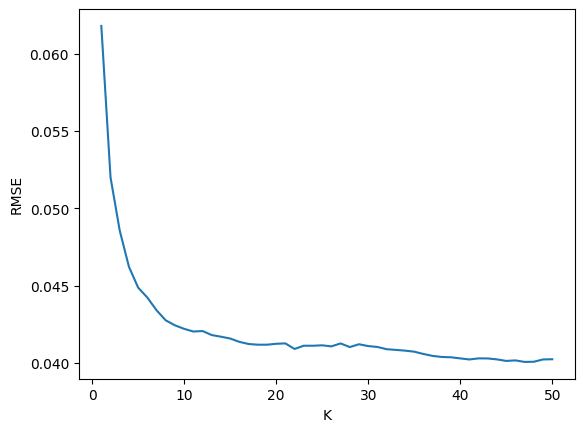

In [3]:
x = (x - x.min()) / (x.max() - x.min())
y = (y - y.min()) / (y.max() - y.min())
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

def knn(x_train, y_train, x_new, k):
    res = []
    for xi in x_new:
        d = np.abs(x_train - xi)          # відстані до всіх точок
        near = np.argsort(d)[:k]          # k найближчих сусідів
        res.append(y_train[near].mean())  # середнє їх значень
    return np.array(res)

def rmse(a, b):
    return np.sqrt(np.mean((a - b) ** 2))

errors = []
for k in range(1, 51):
    pred = knn(x_train, y_train, x_test, k)
    errors.append(rmse(y_test, pred))
    print("K =", k, " RMSE =", round(errors[-1], 4))

best_k = np.argmin(errors) + 1
print("Найкраще K =", best_k, " RMSE =", round(min(errors), 4))

plt.plot(range(1, 51), errors)
plt.xlabel("K")
plt.ylabel("RMSE")
plt.show()

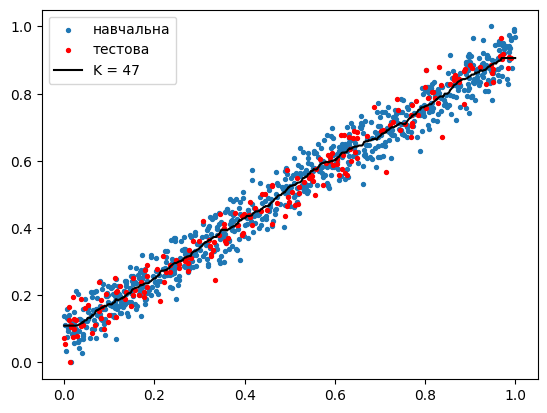

In [4]:
x_line = np.linspace(0, 1, 500)
plt.scatter(x_train, y_train, s=8, label="навчальна")
plt.scatter(x_test, y_test, s=8, color="red", label="тестова")
plt.plot(x_line, knn(x_train, y_train, x_line, best_k), color="black", label="K = " + str(best_k))
plt.legend()
plt.show()